In [1]:
import pandas as pd

In [2]:
dataset = pd.read_csv(r'C:\Users\86134\CISC7204\cisc7204-sugex08-MC566422\Practices02\flight_tracking.csv')
dataset.head()

,hex_ident,altitude(feet),latitude,longitude,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


In [4]:
dataset = dataset.rename(index=str, \
          columns={"latitude": "lat", "longitude": "lon"})
dataset.head()

,hex_ident,altitude(feet),lat,lon,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


In [5]:
from datetime import datetime
def to_epoch(date, time):
    try:
        timestamp = round(datetime.strptime('{} {}'.\
                    format(date, time), \
                    '%Y/%m/%d %H:%M:%S.%f').timestamp())
        return timestamp
    except ValueError:
        return round(datetime.strptime('2017/09/11 17:02:06.418', \
                     '%Y/%m/%d %H:%M:%S.%f').timestamp())

In [6]:
dataset['timestamp'] = dataset.apply(lambda x: to_epoch\
                                    (x['date'], x['time']), \
                                    axis=1)

In [7]:
dataset.head()

,hex_ident,altitude(feet),lat,lon,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign,timestamp
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN,1505120526
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN,1505120527
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT,1505120527
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT,1505120529
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT,1505120530


C:\Users\86134\AppData\Local\Temp\ipykernel_7524\3223828539.py:17: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


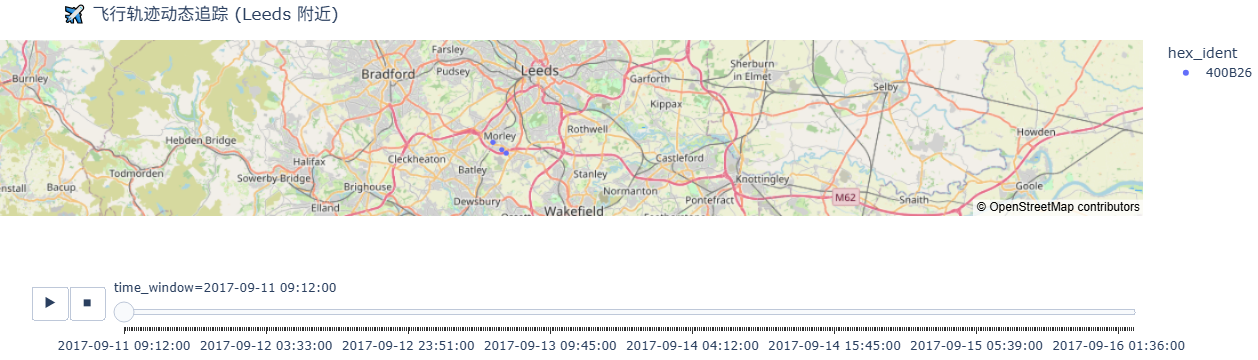

In [10]:
import plotly.express as px
dataset['datetime'] = pd.to_datetime(dataset['timestamp'], unit='s')

df_filtered = dataset[
    (dataset['lon'] >= -3.0) & (dataset['lon'] <= 0.0) & 
    (dataset['lat'] >= 53.7074) & (dataset['lat'] <= 53.8074)
].copy()


df_filtered['time_window'] = df_filtered['datetime'].dt.floor('180s')


fig = px.scatter_mapbox(
    df_filtered,
    lat="lat",
    lon="lon",
    color="hex_ident",              
    animation_frame="time_window",  
    hover_name="hex_ident",
    title="✈️ 飞行轨迹动态追踪 (Leeds 附近)"
)


fig.update_layout(
    mapbox=dict(
        style="open-street-map",    
        center=dict(lat=53.75, lon=-1.5),
        zoom=9
    ),
    margin={"r":0,"t":40,"l":0,"b":0}
)
fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 200
fig.show()